In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('week9_titanic_eda_data.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerID  5000 non-null   int64  
 1   Survived     5000 non-null   int64  
 2   Pclass       5000 non-null   int64  
 3   Name         5000 non-null   object 
 4   Sex          5000 non-null   object 
 5   Age          4700 non-null   float64
 6   SibSp        5000 non-null   int64  
 7   Parch        5000 non-null   int64  
 8   Ticket       5000 non-null   int64  
 9   Fare         5000 non-null   float64
 10  Cabin        4141 non-null   object 
 11  Embarked     5000 non-null   object 
dtypes: float64(2), int64(6), object(4)
memory usage: 468.9+ KB


In [4]:
df.head()

,PassengerID,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,Name_1,female,35.6,2,1,65207,71.42,C123,C
1,2,1,3,Name_2,male,19.5,3,3,67643,57.08,D33,Q
2,3,0,3,Name_3,female,26.1,3,4,50593,152.16,NaN,Q
3,4,0,3,Name_4,female,10.4,3,0,57762,124.40,G6,Q
4,5,0,3,Name_5,female,28.5,1,4,26461,117.36,D33,C


In [5]:
survz_dist = df.describe()

In [6]:
surv_col_dist = print(survz_dist['Survived'])

count    5000.000000
mean        0.499200
std         0.500049
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         1.000000
Name: Survived, dtype: float64


#### There are 5000 passengers.

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
distribution = df['Survived'].value_counts()

In [9]:
print('The distribution for survival is: ', distribution)

The distribution for survival is:  Survived
0    2504
1    2496
Name: count, dtype: int64


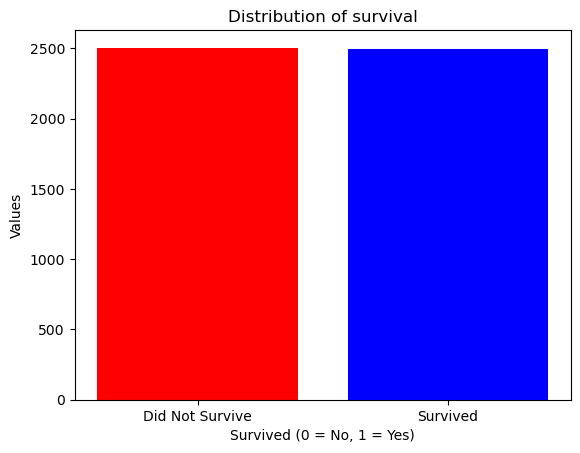

In [10]:
categories = [0, 1]
values = distribution

plt.bar(categories, values, color=['red', 'blue'])
plt.title('Distribution of survival')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Values')
plt.xticks([0, 1], ['Did Not Survive', 'Survived'])
plt.show()

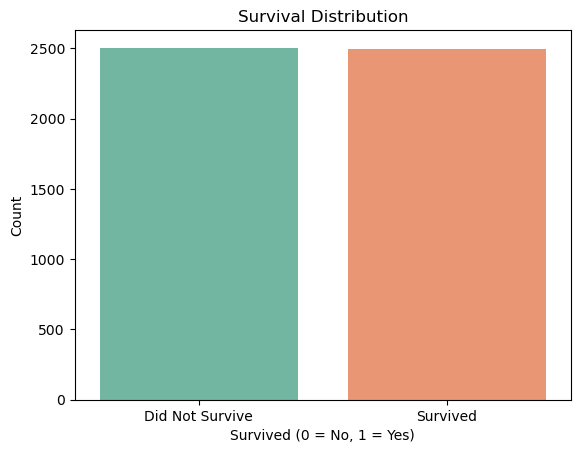

In [11]:
sns.countplot(x='Survived', data=df, palette='Set2')
plt.title('Survival Distribution')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.xticks([0, 1], ['Did Not Survive', 'Survived'])
plt.show()

In [12]:
# distributiin of passenger classes
pclass_col = df['Pclass']
pclass_dist = pclass_col.value_counts()
print(pclass_dist)

Pclass
2    1679
3    1663
1    1658
Name: count, dtype: int64


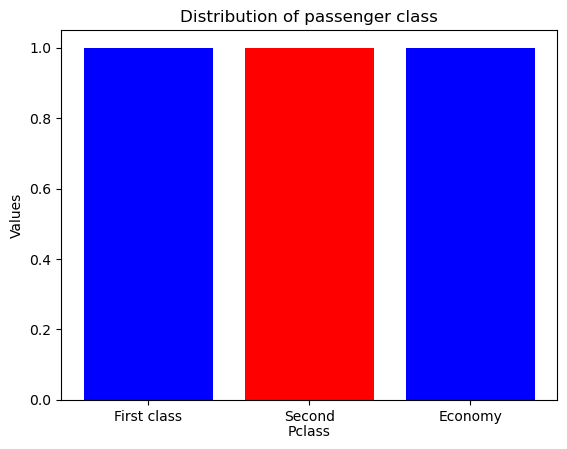

In [13]:
values = pclass_col

plt.bar(values, height=True , color=['red', 'blue', 'green'])
plt.title('Distribution of passenger class')
plt.xlabel('Pclass', labelpad=True)
plt.ylabel('Values')
plt.xticks([1, 2, 3], ['First class', 'Second', 'Economy'])
plt.show()

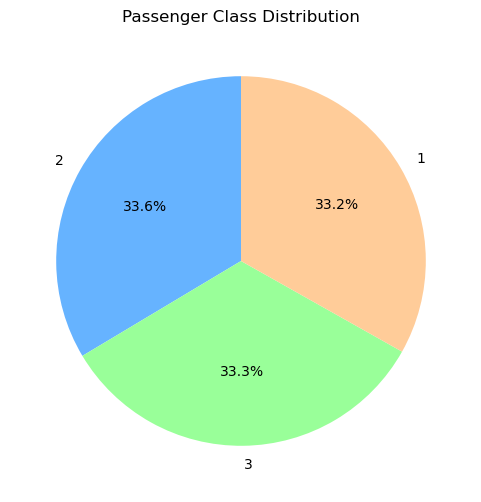

In [14]:
# Pie chart
plt.figure(figsize=(6,6))
pclass_dist.plot.pie(autopct='%1.1f%%', startangle=90, colors=['#66b3ff','#99ff99','#ffcc99'])
plt.title('Passenger Class Distribution')
plt.ylabel('')
plt.show()

# Pie chart of passenger classes
plt.figure(figsize=(6, 6))
plt.pie(pclass_dist, labels=['1st Class', '2nd Class', '3rd Class'], autopct='%1.1f%%', startangle=140, colors=['#66c2a5', '#fc8d62', '#8da0cb'])

plt.title("Passenger Class Distribution")
plt.axis('equal')  # Keeps the pie circular

plt.show()

In [15]:
df['Age']= df['Age'].round(0)

age_dist = df['Age'].value_counts()

In [16]:
print(age_dist)

Age
 26.0    161
 30.0    152
 24.0    151
 36.0    145
 34.0    143
        ... 
-10.0      1
-20.0      1
 79.0      1
-13.0      1
 76.0      1
Name: count, Length: 96, dtype: int64


In [17]:
print("Negative Age Entries:")
df_neg_age = df[df['Age'] < 0]
print(df_neg_age)


Negative Age Entries:
      PassengerID  Survived  Pclass       Name     Sex   Age  SibSp  Parch  \
68             69         1       1    Name_69    male  -3.0      5      4   
111           112         0       3   Name_112    male  -8.0      4      0   
150           151         0       2   Name_151    male  -1.0      0      0   
171           172         0       1   Name_172    male  -5.0      0      2   
203           204         0       1   Name_204    male  -3.0      3      1   
...           ...       ...     ...        ...     ...   ...    ...    ...   
4704         4705         0       1  Name_4705  female  -8.0      3      3   
4841         4842         0       3  Name_4842  female  -3.0      3      1   
4874         4875         1       3  Name_4875  female -16.0      4      3   
4934         4935         1       1  Name_4935  female  -3.0      1      2   
4969         4970         1       2  Name_4970    male -11.0      2      0   

      Ticket    Fare Cabin Embarked  
68 

In [18]:
df_age_cleaned =df[df['Age']>=0]
print("Negative ages deleted: ", df_age_cleaned.head(2))

Negative ages deleted:     PassengerID  Survived  Pclass    Name     Sex   Age  SibSp  Parch  Ticket  \
0            1         0       3  Name_1  female  36.0      2      1   65207   
1            2         1       3  Name_2    male  20.0      3      3   67643   

    Fare Cabin Embarked  
0  71.42  C123        C  
1  57.08   D33        Q  


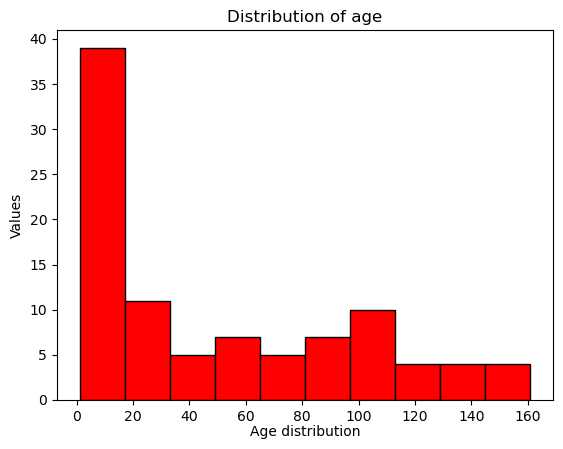

In [21]:
# plot age istribution

values = age_dist

plt.hist(values, bins=10 ,orientation= "vertical",  color=['red'], edgecolor = 'black')
plt.title('Distribution of age')
plt.xlabel('Age distribution', labelpad=True)
plt.ylabel('Values')
plt.show()

C:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


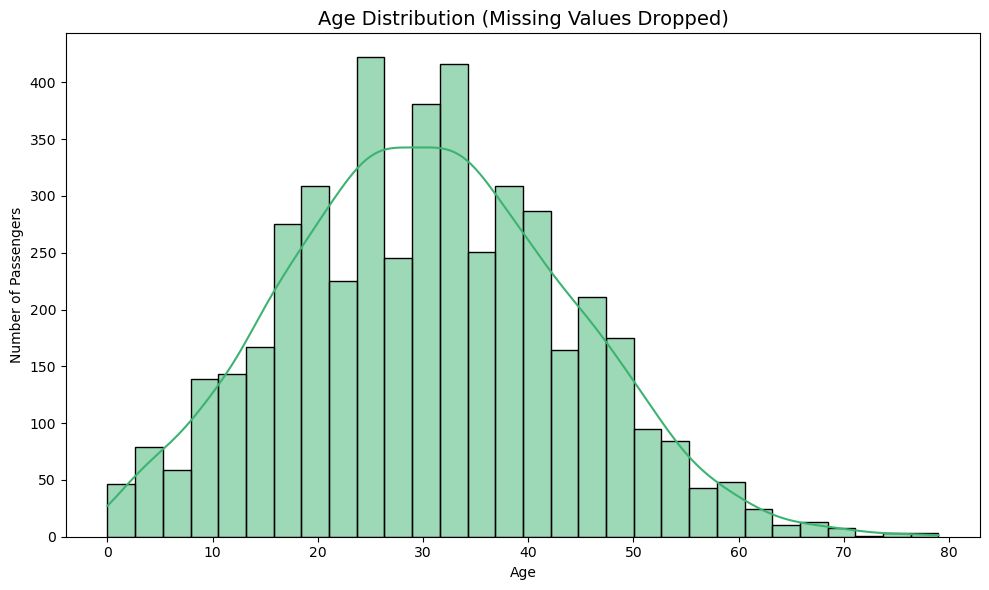

In [23]:
# Plot histogram + KDE using clean data
df_age_cleaned = df_age_cleaned['Age'].dropna()
plt.figure(figsize=(10, 6))
sns.histplot(df_age_cleaned, bins=30, kde=True, color='mediumseagreen', edgecolor='black')

plt.title("Age Distribution (Missing Values Dropped)", fontsize=14)
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

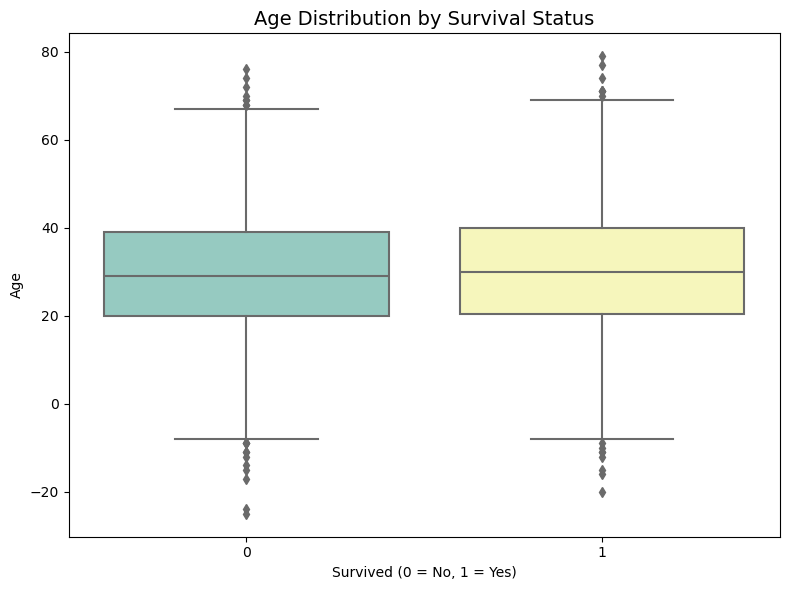

In [26]:
# Boxplot
plt.figure(figsize=(8, 6))
sns.boxplot(x='Survived', y='Age', data=df.dropna(), palette='Set3')

# Labeling
plt.title("Age Distribution by Survival Status", fontsize=14)
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")
plt.tight_layout()
plt.show()